# NLP Lab 1 - Part 2: Emotion Classification

Run all cells from top to bottom. This notebook contains all the code directly; the project Python files are not required.

- Dataset: `avsolatorio/mteb-emotion-avs_triplets` (16,000 sentences).
- Preprocessing: lowercase, alphabetic words, and English stopword removal.
- Random split: **90% training / 10% test**, with **seed 42**.
- Models: NumPy and scikit-learn Naive Bayes; NumPy logistic regression; scikit-learn LogisticRegression and SGDClassifier.

## 1. Imports

In [1]:
import re
import numpy as np
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.naive_bayes import MultinomialNB
from scipy.sparse import csr_matrix
from sklearn.linear_model import LogisticRegression, SGDClassifier
import csv
import json
from pathlib import Path

## 2. Preprocessing and random splitting

In [2]:
DATASET_ID = "avsolatorio/mteb-emotion-avs_triplets"


DATASET_REVISION = "7af7023e3f8be456bfe17846aaed40301048d0fe"


LABEL_NAMES = ["sadness", "joy", "love", "anger", "fear", "surprise"]


def preprocess(text):
    """Lowercase, extract words, and remove common English stopwords."""
    words = re.findall(r"[a-z]+", text.lower())
    words = [word for word in words if word not in ENGLISH_STOP_WORDS]
    return " ".join(words)


def clean_dataset(rows):
    """Apply basic preprocessing and keep every dataset row with its label."""
    texts = []
    labels = []
    for row in rows:
        texts.append(preprocess(row["text"]))
        labels.append(int(row["label"]))

    print(f"Dataset: {len(texts):,} sentences")
    return texts, np.asarray(labels, dtype=int)


def random_split(texts, labels, test_size=0.1, seed=42):
    """Shuffle all rows and reserve 10% for testing by default.

    Returns train_texts, test_texts, train_labels, and test_labels.
    The same seed produces the same split and sentence order.
    """
    labels = np.asarray(labels)
    random_generator = np.random.default_rng(seed)
    shuffled_indices = random_generator.permutation(len(texts))
    number_of_test_samples = int(np.ceil(len(texts) * test_size))

    test_indices = shuffled_indices[:number_of_test_samples]
    train_indices = shuffled_indices[number_of_test_samples:]

    train_texts = [texts[index] for index in train_indices]
    test_texts = [texts[index] for index in test_indices]
    train_labels = labels[train_indices]
    test_labels = labels[test_indices]
    return train_texts, test_texts, train_labels, test_labels


def load_and_split(test_size=0.1, seed=42):
    """Download once into Hugging Face's cache, then clean and split the data."""
    from datasets import load_dataset

    dataset = load_dataset(DATASET_ID, split="train", revision=DATASET_REVISION)
    texts, labels = clean_dataset(dataset)
    return random_split(texts, labels, test_size=test_size, seed=seed)

## 3. NumPy Naive Bayes

In [ ]:
class NumpyMultinomialNB:
    """Learn emotion probabilities from word counts in cleaned sentences.

    alpha controls additive smoothing. alpha=1 gives Laplace smoothing.
    Attributes ending in an underscore hold values learned during fit().
    """

    def __init__(self, alpha=1.0):
        self.alpha = float(alpha)

    def fit(self, texts, labels):
        texts = list(texts)
        labels = np.array(labels)

        # 1. Get classes
        self.classes_ = np.unique(labels)

        # 2. Build vocabulary
        words = set()
        for text in texts:
            for word in text.split():
                words.add(word)

        self.vocabulary_ = {}
        for i, word in enumerate(sorted(words)):
            self.vocabulary_[word] = i

        num_classes = len(self.classes_)
        vocab_size = len(self.vocabulary_)

        # 3. Create counters
        self.class_count_ = np.zeros(num_classes)
        self.feature_count_ = np.zeros((num_classes, vocab_size))

        # 4. Count sentences and words for each class
        for text, label in zip(texts, labels):
            class_index = np.where(self.classes_ == label)[0][0]

            self.class_count_[class_index] += 1

            for word in text.split():
                word_index = self.vocabulary_[word]
                self.feature_count_[class_index][word_index] += 1

        # 5. Calculate P(class)
        class_prob = self.class_count_ / len(texts)
        self.class_log_prior_ = np.log(class_prob)

        # 6. Calculate P(word | class) with Laplace smoothing
        word_counts = self.feature_count_ + self.alpha

        total_words = word_counts.sum(axis=1, keepdims=True)

        word_prob = word_counts / total_words

        self.feature_log_prob_ = np.log(word_prob)

        return self

    def decision_function(self, texts):
        """Return a log posterior score for every sentence and class.

        score = log P(class) + sum of log P(word | class) for every word.
        Log probabilities avoid multiplying many very small numbers.
        """
        texts = list(texts)
        scores = np.tile(self.class_log_prior_, (len(texts), 1))

        for sentence_index, text in enumerate(texts):
            for word in text.split():
                # Ignore words that never appeared in training.
                if word in self.vocabulary_:
                    word_index = self.vocabulary_[word]
                    scores[sentence_index] += self.feature_log_prob_[:, word_index]

        # Empty or entirely unknown sentences keep their class prior scores.
        return scores

    def predict(self, texts):
        """Choose the class with the largest score for each sentence."""
        scores = self.decision_function(texts)
        best_class_indices = scores.argmax(axis=1)
        return self.classes_[best_class_indices]

    def predict_proba(self, texts):
        """Convert log scores to probabilities that sum to one per sentence."""
        scores = self.decision_function(texts)
        scores = scores - scores.max(axis=1, keepdims=True)
        probabilities = np.exp(scores)
        return probabilities / probabilities.sum(axis=1, keepdims=True)

## 4. Scikit-learn Naive Bayes

In [4]:
class SklearnMultinomialNB:
    """Expose the same fit/predict interface as the NumPy implementation."""

    def __init__(self, alpha=1.0, vocabulary=None):
        # Text has already been cleaned, so split on spaces without changing it.
        # An optional shared vocabulary ensures both models use the same words.
        self.vectorizer = CountVectorizer(
            vocabulary=vocabulary,
            lowercase=False,
            preprocessor=None,
            tokenizer=str.split,
            token_pattern=None,
        )
        self.model = MultinomialNB(alpha=alpha)

    def fit(self, texts, labels):
        """Convert training sentences to word counts, then train Naive Bayes."""
        word_counts = self.vectorizer.fit_transform(texts)
        self.model.fit(word_counts, labels)
        return self

    def predict(self, texts):
        """Use the fitted vocabulary to classify new cleaned sentences."""
        word_counts = self.vectorizer.transform(texts)
        return self.model.predict(word_counts)

    def predict_proba(self, texts):
        """Return a probability for every class in each cleaned sentence."""
        word_counts = self.vectorizer.transform(texts)
        return self.model.predict_proba(word_counts)

## 5. Binary bigram features

In [5]:
class BigramVectorizer:
    """Map sentences to sparse binary vectors using a training-set vocabulary."""

    def fit(self, texts):
        bigrams = set()
        for text in texts:
            tokens = text.split()
            bigrams.update(zip(tokens, tokens[1:]))
        self.vocabulary_ = {
            bigram: index for index, bigram in enumerate(sorted(bigrams))
        }
        return self

    def transform(self, texts):
        if not hasattr(self, "vocabulary_"):
            raise ValueError("fit the vectorizer before transform")
        row_indices, column_indices = [], []
        for row, text in enumerate(texts):
            tokens = text.split()
            columns = {
                self.vocabulary_[bigram]
                for bigram in zip(tokens, tokens[1:])
                if bigram in self.vocabulary_
            }
            row_indices.extend([row] * len(columns))
            column_indices.extend(columns)
        data = np.ones(len(row_indices), dtype=np.float64)
        return csr_matrix(
            (data, (row_indices, column_indices)),
            shape=(len(texts), len(self.vocabulary_)), dtype=np.float64,
        )

    def fit_transform(self, texts):
        texts = list(texts)
        self.fit(texts)
        return self.transform(texts)

## 6. NumPy logistic regression

The improved model keeps minibatch gradient descent and shuffles every epoch.
Defaults: **learning rate 10.0, 60 epochs, batch size 128, seed 42**.
Optional L2 regularization is supported; the selected default is `l2=0.0`.
`loss_history_` records the updated model's cross-entropy after each epoch.

Settings were selected by macro F1 using **12,960 fitting rows and 1,440 validation rows**,
all taken from the outer training partition. The validation vocabulary was fitted only on
those 12,960 fitting rows. Final training below uses all 14,400 training rows.

| Learning rate | Epochs | L2 | Validation accuracy | Validation macro F1 |
| ---: | ---: | ---: | ---: | ---: |
| 0.1 | 30 | 0.0 | 0.5090 | 0.2143 |
| 1.0 | 60 | 0.0 | 0.7090 | 0.6000 |
| 5.0 | 60 | 0.0 | 0.7236 | 0.6437 |
| 10.0 | 60 | 0.0 | 0.7306 | 0.6599 |
| 10.0 | 60 | 0.0001 | 0.7042 | 0.6065 |

In [6]:
class NumpyLogisticRegression:
    # Defaults selected using validation rows from the training partition only.
    def __init__(self, learning_rate=10.0, epochs=60, batch_size=128, seed=42, l2=0.0):
        self.learning_rate = float(learning_rate)
        self.epochs = int(epochs)
        self.batch_size = int(batch_size)
        self.seed = seed
        self.l2 = float(l2)

    @staticmethod
    def _softmax(scores):
        scores = scores - scores.max(axis=1, keepdims=True) 
        exp_scores = np.exp(scores)
        return exp_scores / exp_scores.sum(axis=1, keepdims=True)

    def fit(self, features, labels):
        labels = np.asarray(labels)
        if features.shape[0] != len(labels):
            raise ValueError("features and labels must have the same number of rows")
        self.classes_ = np.unique(labels)
        encoded = np.searchsorted(self.classes_, labels)
        rows, feature_count = features.shape
        class_count = len(self.classes_)
        self.weights_ = np.zeros((feature_count, class_count))
        self.bias_ = np.zeros(class_count)
        self.loss_history_ = []

        generator = np.random.default_rng(self.seed)
        for _ in range(self.epochs):
            shuffled = generator.permutation(rows)
            for start in range(0, rows, self.batch_size):
                indices = shuffled[start:start + self.batch_size]
                batch = features[indices]
                targets = encoded[indices]
                errors = self._softmax(batch @ self.weights_ + self.bias_)
                errors[np.arange(len(indices)), targets] -= 1.0
                errors /= len(indices)
                weight_gradient = np.asarray(batch.T @ errors)
                if self.l2 > 0:
                    weight_gradient += self.l2 * self.weights_
                bias_gradient = errors.sum(axis=0)
                self.weights_ -= self.learning_rate * weight_gradient
                self.bias_ -= self.learning_rate * bias_gradient
            # Record the loss of the updated model, not a mix of earlier batches.
            probabilities = self.predict_proba(features)
            correct_class_probabilities = probabilities[np.arange(rows), encoded]
            loss = -np.log(np.clip(correct_class_probabilities, 1e-15, 1.0)).mean()
            loss += 0.5 * self.l2 * np.sum(self.weights_ ** 2)
            self.loss_history_.append(float(loss))
        return self

    def predict_proba(self, features):
        if not hasattr(self, "weights_"):
            raise ValueError("fit the model before prediction")
        return self._softmax(features @ self.weights_ + self.bias_)

    def predict(self, features):
        return self.classes_[self.predict_proba(features).argmax(axis=1)]

## 7. Scikit-learn logistic regression and SGD

In [7]:
class SklearnLogisticRegression:
    def __init__(self, max_iter=1000, random_state=42):
        self.model = LogisticRegression(max_iter=max_iter, random_state=random_state)

    def fit(self, features, labels):
        self.model.fit(features, labels)
        return self

    def predict(self, features):
        return self.model.predict(features)


class SklearnSGDClassifier:
    def __init__(self, max_iter=1000, random_state=42):
        self.model = SGDClassifier(
            loss="log_loss", max_iter=max_iter, tol=1e-3,
            random_state=random_state,
        )

    def fit(self, features, labels):
        self.model.fit(features, labels)
        return self

    def predict(self, features):
        return self.model.predict(features)

## 8. Evaluation metrics

In [8]:
MODEL_NAMES = {
    "numpy": "NumPy Naive Bayes",
    "sklearn": "scikit-learn Naive Bayes",
    "numpy_logistic": "NumPy Logistic Regression",
    "sklearn_logistic": "scikit-learn LogisticRegression",
    "sklearn_sgd": "scikit-learn SGDClassifier (log loss)",
}


def confusion_matrix(y_true, y_pred, labels):
    """Count predictions: rows are true classes, columns are predicted classes."""
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    labels = list(labels)

    if y_true.ndim != 1 or y_pred.ndim != 1 or y_true.shape != y_pred.shape:
        raise ValueError("true and predicted labels must be equally sized 1D arrays")
    if not labels or len(set(labels)) != len(labels):
        raise ValueError("labels must be nonempty and unique")

    label_to_index = {label: index for index, label in enumerate(labels)}
    matrix = np.zeros((len(labels), len(labels)), dtype=np.int64)

    for true_label, predicted_label in zip(y_true, y_pred):
        if true_label not in label_to_index or predicted_label not in label_to_index:
            raise ValueError("a true or predicted label is missing from labels")
        row = label_to_index[true_label]
        column = label_to_index[predicted_label]
        matrix[row, column] += 1

    return matrix


def safe_divide(numerator, denominator):
    """Divide element by element, returning zero wherever the denominator is zero."""
    return np.divide(
        numerator,
        denominator,
        out=np.zeros_like(numerator, dtype=float),
        where=denominator != 0,
    )


def metrics_from_confusion_matrix(matrix):
    """Calculate per-class precision, recall, F1, macro averages, and accuracy."""
    matrix = np.asarray(matrix)
    if matrix.ndim != 2 or matrix.shape[0] != matrix.shape[1] or matrix.shape[0] == 0:
        raise ValueError("confusion matrix must be nonempty and square")
    if not np.all(np.isfinite(matrix)) or np.any(matrix < 0):
        raise ValueError("confusion matrix counts must be finite and nonnegative")
    if np.any(matrix != np.floor(matrix)):
        raise ValueError("confusion matrix counts must be integers")

    true_positives = np.diag(matrix).astype(float)
    actual_counts = matrix.sum(axis=1)       # Row totals: actual sentences per class.
    predicted_counts = matrix.sum(axis=0)    # Column totals: predictions per class.
    false_positives = predicted_counts - true_positives
    false_negatives = actual_counts - true_positives

    # Precision = TP / (TP + FP), recall = TP / (TP + FN).
    precision = safe_divide(true_positives, true_positives + false_positives)
    recall = safe_divide(true_positives, true_positives + false_negatives)
    f1 = safe_divide(2 * precision * recall, precision + recall)

    total_predictions = matrix.sum()
    accuracy = 0.0
    if total_predictions > 0:
        accuracy = float(true_positives.sum() / total_predictions)

    # Macro averages give every class equal weight, including rare classes.
    return {
        "confusion_matrix": matrix,
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "support": actual_counts,
        "macro_precision": float(precision.mean()),
        "macro_recall": float(recall.mean()),
        "macro_f1": float(f1.mean()),
        "accuracy": accuracy,
    }


def evaluate(y_true, y_pred, labels):
    """Build the confusion matrix, then derive all metrics from its counts."""
    matrix = confusion_matrix(y_true, y_pred, labels)
    return metrics_from_confusion_matrix(matrix)


def validate_metrics(y_true, y_pred, result, labels):
    """Check the NumPy calculations against the required sklearn functions.

    sklearn is used only as a reference here, not to calculate our own metrics.
    """
    from sklearn.metrics import confusion_matrix as sklearn_confusion_matrix
    from sklearn.metrics import f1_score, precision_score, recall_score

    expected_matrix = sklearn_confusion_matrix(y_true, y_pred, labels=labels)
    np.testing.assert_array_equal(result["confusion_matrix"], expected_matrix)

    reference_functions = {
        "precision": precision_score,
        "recall": recall_score,
        "f1": f1_score,
    }
    for metric_name, metric_function in reference_functions.items():
        expected_per_class = metric_function(
            y_true, y_pred, labels=labels, average=None, zero_division=0,
        )
        expected_macro = metric_function(
            y_true, y_pred, labels=labels, average="macro", zero_division=0,
        )
        np.testing.assert_allclose(result[metric_name], expected_per_class, rtol=1e-12, atol=1e-12)
        np.testing.assert_allclose(result["macro_" + metric_name], expected_macro, rtol=1e-12, atol=1e-12)


def evaluate_models(y_true, predictions_by_model, label_names):
    """Evaluate any classifiers using the same numeric labels (0, 1, ...)."""
    labels = np.arange(len(label_names))
    results = {}

    for model_name, predictions in predictions_by_model.items():
        model_results = evaluate(y_true, predictions, labels)
        validate_metrics(y_true, predictions, model_results, labels)
        results[model_name] = model_results

    return results


def format_evaluation(name, result, label_names):
    """Create one readable table for both the terminal and summary.txt."""
    lines = [
        f"\n{name}",
        f"{'Class':12} {'Precision':>10} {'Recall':>10} {'F1':>10} {'Support':>9}",
    ]
    for index, label in enumerate(label_names):
        lines.append(
            f"{label:12} {result['precision'][index]:10.4f} "
            f"{result['recall'][index]:10.4f} {result['f1'][index]:10.4f} "
            f"{result['support'][index]:9d}"
        )

    lines.extend([
        f"{'Macro avg':12} {result['macro_precision']:10.4f} "
        f"{result['macro_recall']:10.4f} {result['macro_f1']:10.4f}",
        f"Accuracy: {result['accuracy']:.2%}",
        "Confusion matrix (rows=true, columns=predicted):",
        "Class order: " + ", ".join(label_names),
        str(result["confusion_matrix"]),
    ])
    return "\n".join(lines)


def print_evaluation(name, result, label_names):
    print(format_evaluation(name, result, label_names))

## 9. Save results

These functions save labeled confusion matrices (PNG and CSV), metrics (CSV and JSON), predictions, and a text summary.

In [9]:
def save_confusion_plot(matrix, label_names, title, path):
    """Save a labeled PNG without opening a plot window."""
    from matplotlib.backends.backend_agg import FigureCanvasAgg
    from matplotlib.figure import Figure

    figure = Figure(figsize=(8, 6.5), layout="constrained")
    FigureCanvasAgg(figure)
    axis = figure.subplots()
    image = axis.imshow(matrix, cmap="Blues", vmin=0)
    figure.colorbar(image, ax=axis, label="Number of sentences")
    axis.set(
        xticks=range(len(label_names)),
        yticks=range(len(label_names)),
        xticklabels=label_names,
        yticklabels=label_names,
        xlabel="Predicted emotion",
        ylabel="True emotion",
        title=title,
    )

    # Show each count; use white text on dark cells so it remains readable.
    threshold = matrix.max() / 2
    for row in range(len(label_names)):
        for column in range(len(label_names)):
            text_color = "white" if matrix[row, column] > threshold else "black"
            axis.text(
                column, row, str(matrix[row, column]),
                ha="center", va="center", color=text_color,
            )
    figure.savefig(path, dpi=180)


def save_confusion_csv(path, matrix, label_names):
    """Write the same confusion matrix as a table with labeled rows and columns."""
    with path.open("w", encoding="utf-8", newline="") as file:
        writer = csv.writer(file)
        writer.writerow(["true / predicted", *label_names])
        for label, counts in zip(label_names, matrix):
            writer.writerow([label, *counts.tolist()])


def save_metrics_csv(path, results, label_names):
    with path.open("w", encoding="utf-8", newline="") as file:
        writer = csv.writer(file)
        writer.writerow(["model", "class", "precision", "recall", "f1", "support"])

        for model_name, result in results.items():
            for index, label in enumerate(label_names):
                writer.writerow([
                    model_name, label,
                    result["precision"][index], result["recall"][index],
                    result["f1"][index], result["support"][index],
                ])
            writer.writerow([
                model_name, "macro_average",
                result["macro_precision"], result["macro_recall"],
                result["macro_f1"], int(result["support"].sum()),
            ])


def save_metrics_json(path, results, label_names, configuration):
    """Convert NumPy arrays to ordinary lists so JSON can store them."""
    serializable_results = {}
    for model_name, result in results.items():
        serializable_results[model_name] = {}
        for metric_name, value in result.items():
            if isinstance(value, np.ndarray):
                value = value.tolist()
            serializable_results[model_name][metric_name] = value

    document = {
        "label_order": label_names,
        "configuration": configuration,
        "models": serializable_results,
    }
    path.write_text(json.dumps(document, indent=2) + "\n", encoding="utf-8")


def save_predictions_csv(path, texts, y_true, predictions, label_names):
    """Store each test sentence alongside its actual and predicted emotions."""
    model_names = list(predictions)
    with path.open("w", encoding="utf-8", newline="") as file:
        writer = csv.writer(file)
        prediction_columns = [f"{name}_prediction" for name in model_names]
        writer.writerow(["cleaned_text", "true_emotion", *prediction_columns])

        for index, text in enumerate(texts):
            true_emotion = label_names[int(y_true[index])]
            row = [text, true_emotion]
            for model_name in model_names:
                predicted_label = int(predictions[model_name][index])
                row.append(label_names[predicted_label])
            writer.writerow(row)


def save_summary(path, results, label_names, configuration):
    lines = [
        "Emotion classification results",
        f"Training: {configuration['train_size']:,}; test: {configuration['test_size']:,}",
    ]
    for model_name, result in results.items():
        display_name = MODEL_NAMES.get(model_name, model_name.replace("_", " "))
        lines.append(format_evaluation(display_name, result, label_names))

    lines.extend([
        f"\nPrediction agreement: {configuration['prediction_agreement']:.2%}",
        "All NumPy metrics were verified against scikit-learn.",
    ])
    path.write_text("\n".join(lines) + "\n", encoding="utf-8")


def save_results(directory, results, predictions, texts, y_true, label_names, train_size):
    """Save matrices, metrics, and predictions for any number of classifiers."""
    directory = Path(directory)
    directory.mkdir(parents=True, exist_ok=True)
    prediction_arrays = np.array(list(predictions.values()))
    all_models_agree = np.all(prediction_arrays == prediction_arrays[0], axis=0)
    configuration = {
        "train_size": train_size,
        "test_size": len(y_true),
        "prediction_agreement": float(np.mean(all_models_agree)),
        "sklearn_validation_passed": True,
    }

    for model_name, result in results.items():
        matrix = result["confusion_matrix"]
        display_name = MODEL_NAMES.get(model_name, model_name.replace("_", " "))
        save_confusion_csv(directory / f"{model_name}_confusion_matrix.csv", matrix, label_names)
        save_confusion_plot(
            matrix, label_names, display_name,
            directory / f"{model_name}_confusion_matrix.png",
        )

    save_metrics_csv(directory / "metrics.csv", results, label_names)
    save_metrics_json(directory / "metrics.json", results, label_names, configuration)
    save_predictions_csv(directory / "predictions.csv", texts, y_true, predictions, label_names)
    save_summary(directory / "summary.txt", results, label_names, configuration)
    return directory.resolve()

## 10. Load and split the dataset

In [10]:
# 1. Random split: 90% training, 10% testing, seed 42.
train_texts, test_texts, train_labels, test_labels = load_and_split(test_size=0.1, seed=42)
print(f"Training: {len(train_texts):,}; test: {len(test_texts):,}")

C:\Users\kero samy\AppData\Roaming\Python\Python312\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Dataset: 16,000 sentences
Training: 14,400; test: 1,600


## 11. Train Naive Bayes

In [11]:
# 2. Train the NumPy and scikit-learn models.
numpy_model = NumpyMultinomialNB(alpha=1.0)
numpy_model.fit(train_texts, train_labels)

sklearn_model = SklearnMultinomialNB(alpha=1.0, vocabulary=numpy_model.vocabulary_)
sklearn_model.fit(train_texts, train_labels)

print("Both Naive Bayes models trained.")

Both Naive Bayes models trained.


## 12. Train logistic regression on binary bigrams

In [12]:
# 3. Build binary bigram features from training data only, then compare
# three logistic regression implementations on identical sparse matrices.
vectorizer = BigramVectorizer()
train_bigrams = vectorizer.fit_transform(train_texts)
test_bigrams = vectorizer.transform(test_texts)

numpy_logistic = NumpyLogisticRegression()
numpy_logistic.fit(train_bigrams, train_labels)
sklearn_logistic = SklearnLogisticRegression()
sklearn_logistic.fit(train_bigrams, train_labels)
sklearn_sgd = SklearnSGDClassifier()
sklearn_sgd.fit(train_bigrams, train_labels)

print("All three logistic classifiers trained.")
print("Training bigram features:", train_bigrams.shape)

All three logistic classifiers trained.
Training bigram features: (14400, 78170)


## 13. Evaluate all models and save results

In [13]:
# 4. Evaluate all models and save the results.
predictions = {
    "numpy": numpy_model.predict(test_texts),
    "sklearn": sklearn_model.predict(test_texts),
    "numpy_logistic": numpy_logistic.predict(test_bigrams),
    "sklearn_logistic": sklearn_logistic.predict(test_bigrams),
    "sklearn_sgd": sklearn_sgd.predict(test_bigrams),
}
results = evaluate_models(test_labels, predictions, LABEL_NAMES)
for model_name, metrics in results.items():
    print_evaluation(MODEL_NAMES[model_name], metrics, LABEL_NAMES)

results_folder = Path.cwd() / "results"
save_results(
    results_folder, results, predictions, test_texts, test_labels,
    LABEL_NAMES, train_size=len(train_texts),
)
print(f"\nResults saved to: {results_folder}")


NumPy Naive Bayes
Class         Precision     Recall         F1   Support
sadness          0.7596     0.9193     0.8319       471
joy              0.7267     0.9558     0.8257       498
love             0.9362     0.3165     0.4731       139
anger            0.8580     0.6814     0.7596       204
fear             0.8868     0.6184     0.7287       228
surprise         1.0000     0.1167     0.2090        60
Macro avg        0.8612     0.6014     0.6380
Accuracy: 77.50%
Confusion matrix (rows=true, columns=predicted):
Class order: sadness, joy, love, anger, fear, surprise
[[433  24   2   8   4   0]
 [ 19 476   1   1   1   0]
 [ 24  69  44   2   0   0]
 [ 34  27   0 139   4   0]
 [ 45  31   0  11 141   0]
 [ 15  28   0   1   9   7]]

scikit-learn Naive Bayes
Class         Precision     Recall         F1   Support
sadness          0.7596     0.9193     0.8319       471
joy              0.7267     0.9558     0.8257       498
love             0.9362     0.3165     0.4731       139
anger    


Results saved to: C:\Users\kero samy\OneDrive - Alexandria University\Desktop\NLP Lab\results


## 14. Model comparison: accuracy and macro F1

Macro F1 is the average of the six per-class F1 scores, giving every emotion equal weight. It is calculated with NumPy and checked against `sklearn.metrics.f1_score(..., average="macro")`.

In [14]:
comparison_rows = []
print(f"{'Model':48} {'Accuracy':>10} {'Macro F1':>10}")
for model_name, metrics in results.items():
    display_name = MODEL_NAMES[model_name]
    print(f"{display_name:48} {metrics['accuracy']:10.2%} {metrics['macro_f1']:10.4f}")
    comparison_rows.append([display_name, metrics["accuracy"], metrics["macro_f1"]])

with (results_folder / "model_comparison.csv").open("w", encoding="utf-8", newline="") as file:
    writer = csv.writer(file)
    writer.writerow(["model", "accuracy", "macro_f1"])
    writer.writerows(comparison_rows)

Model                                              Accuracy   Macro F1
NumPy Naive Bayes                                    77.50%     0.6380
scikit-learn Naive Bayes                             77.50%     0.6380
NumPy Logistic Regression                            72.81%     0.6788
scikit-learn LogisticRegression                      71.12%     0.6391
scikit-learn SGDClassifier (log loss)                70.31%     0.6219


## 15. View the confusion matrices

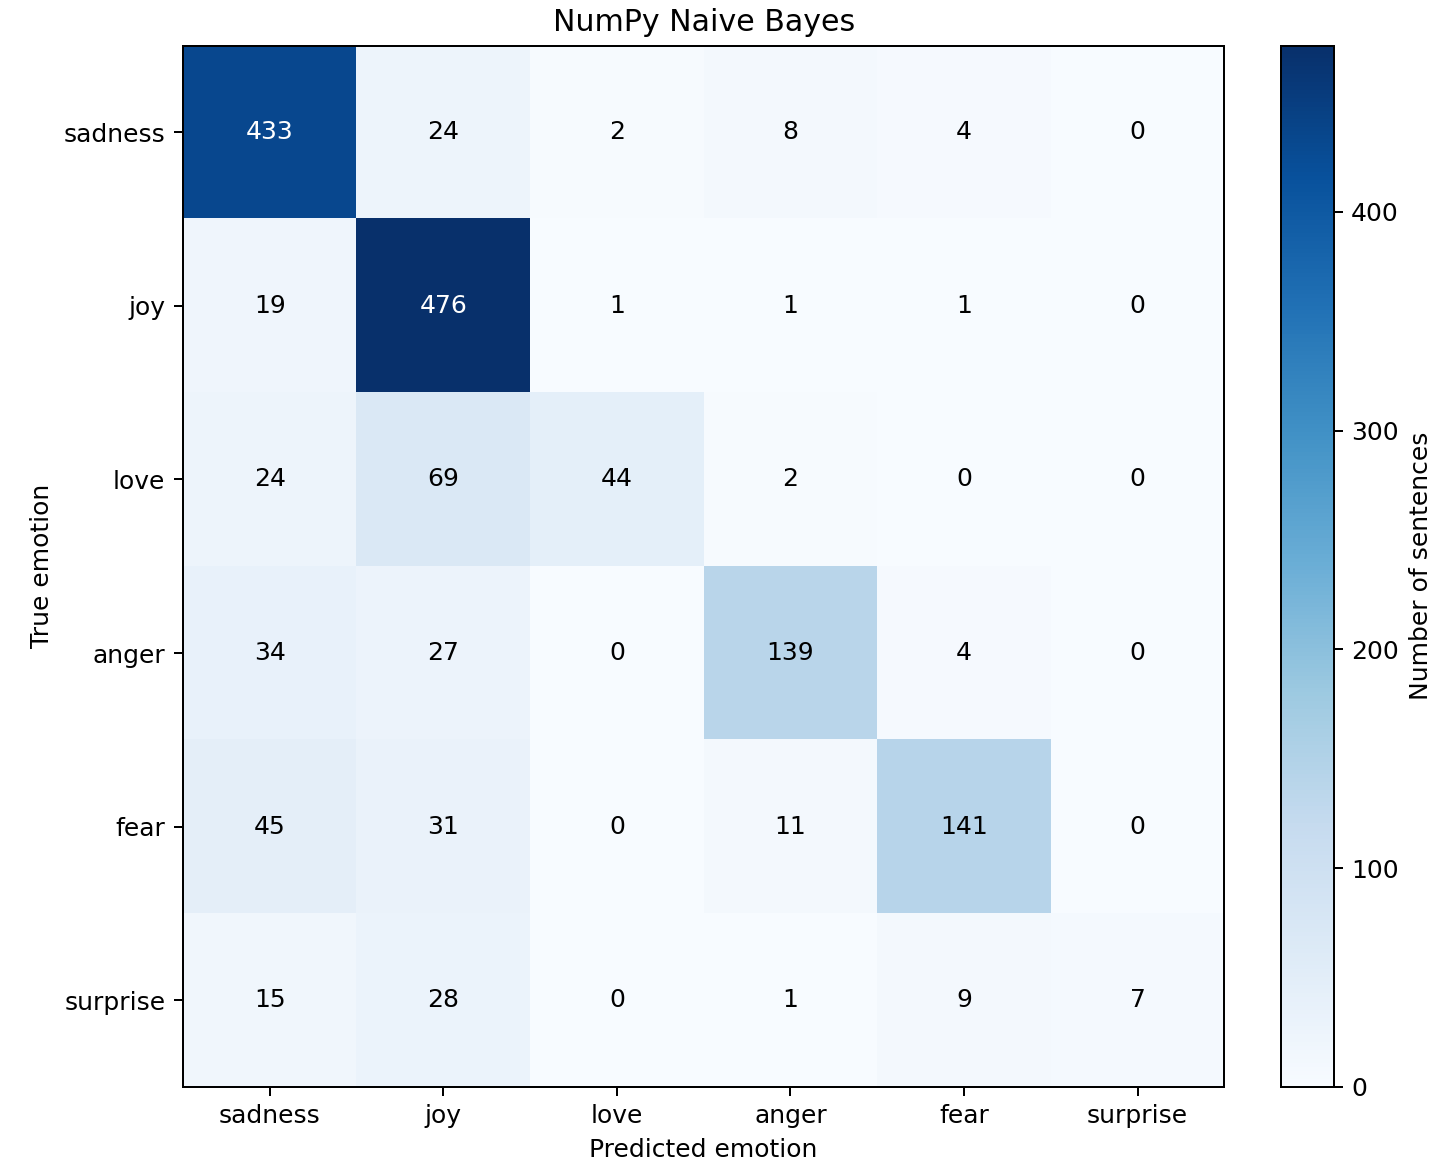

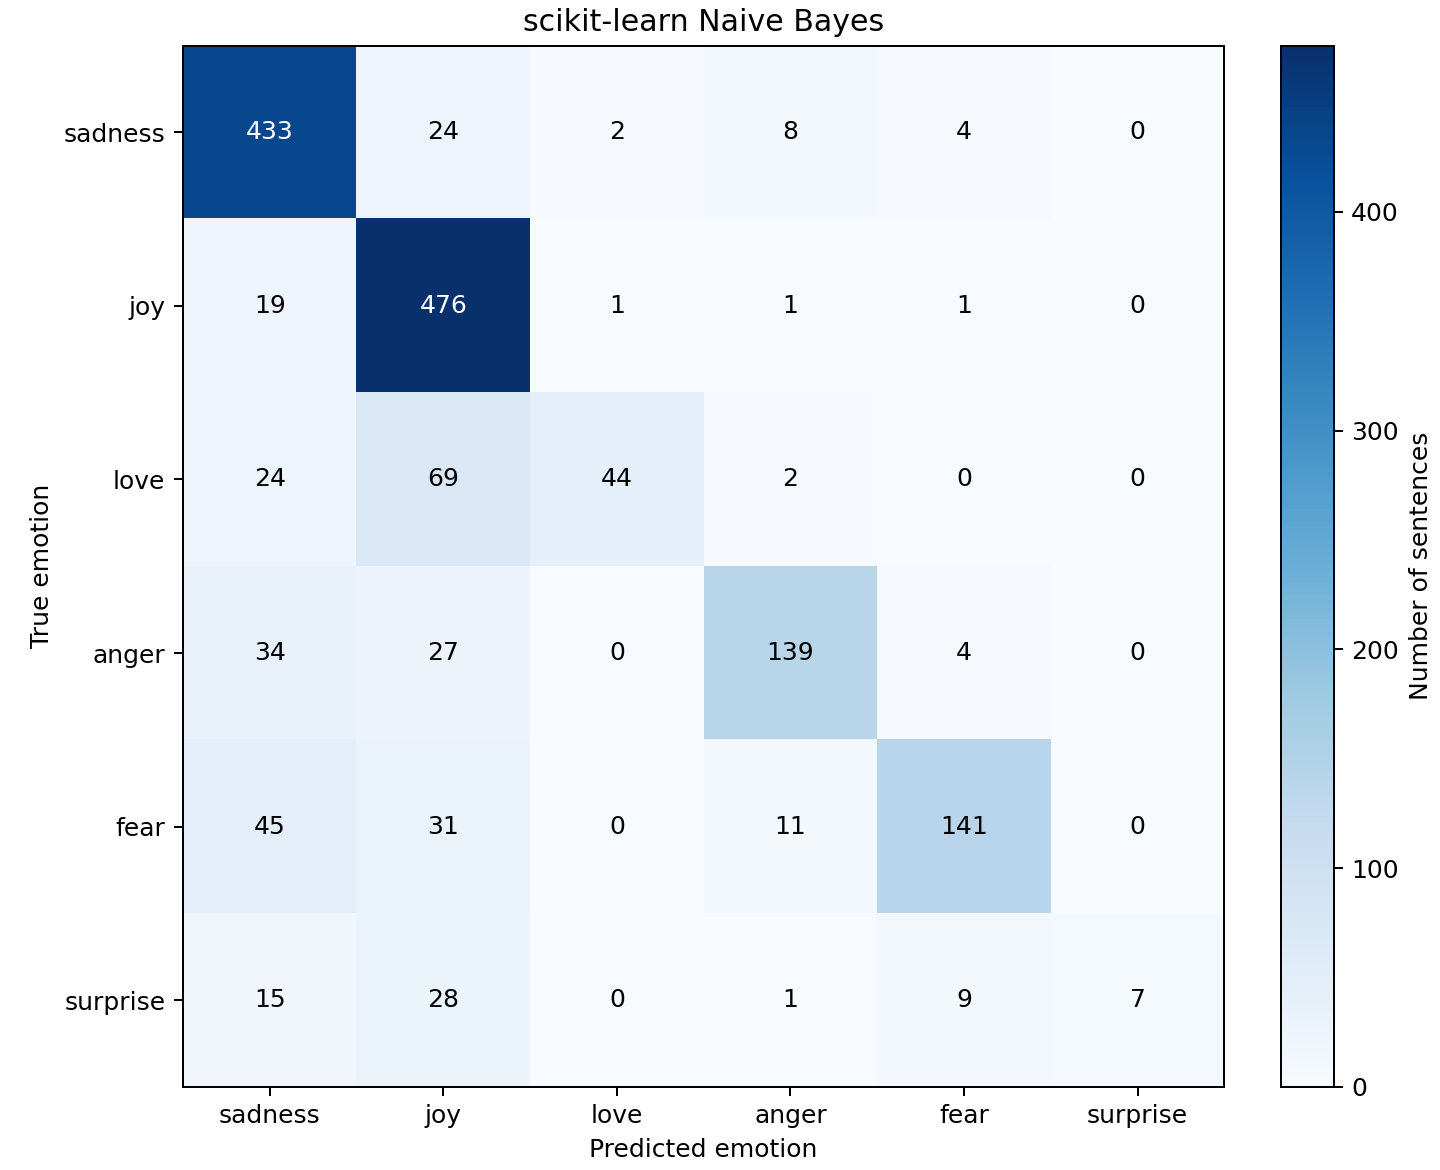

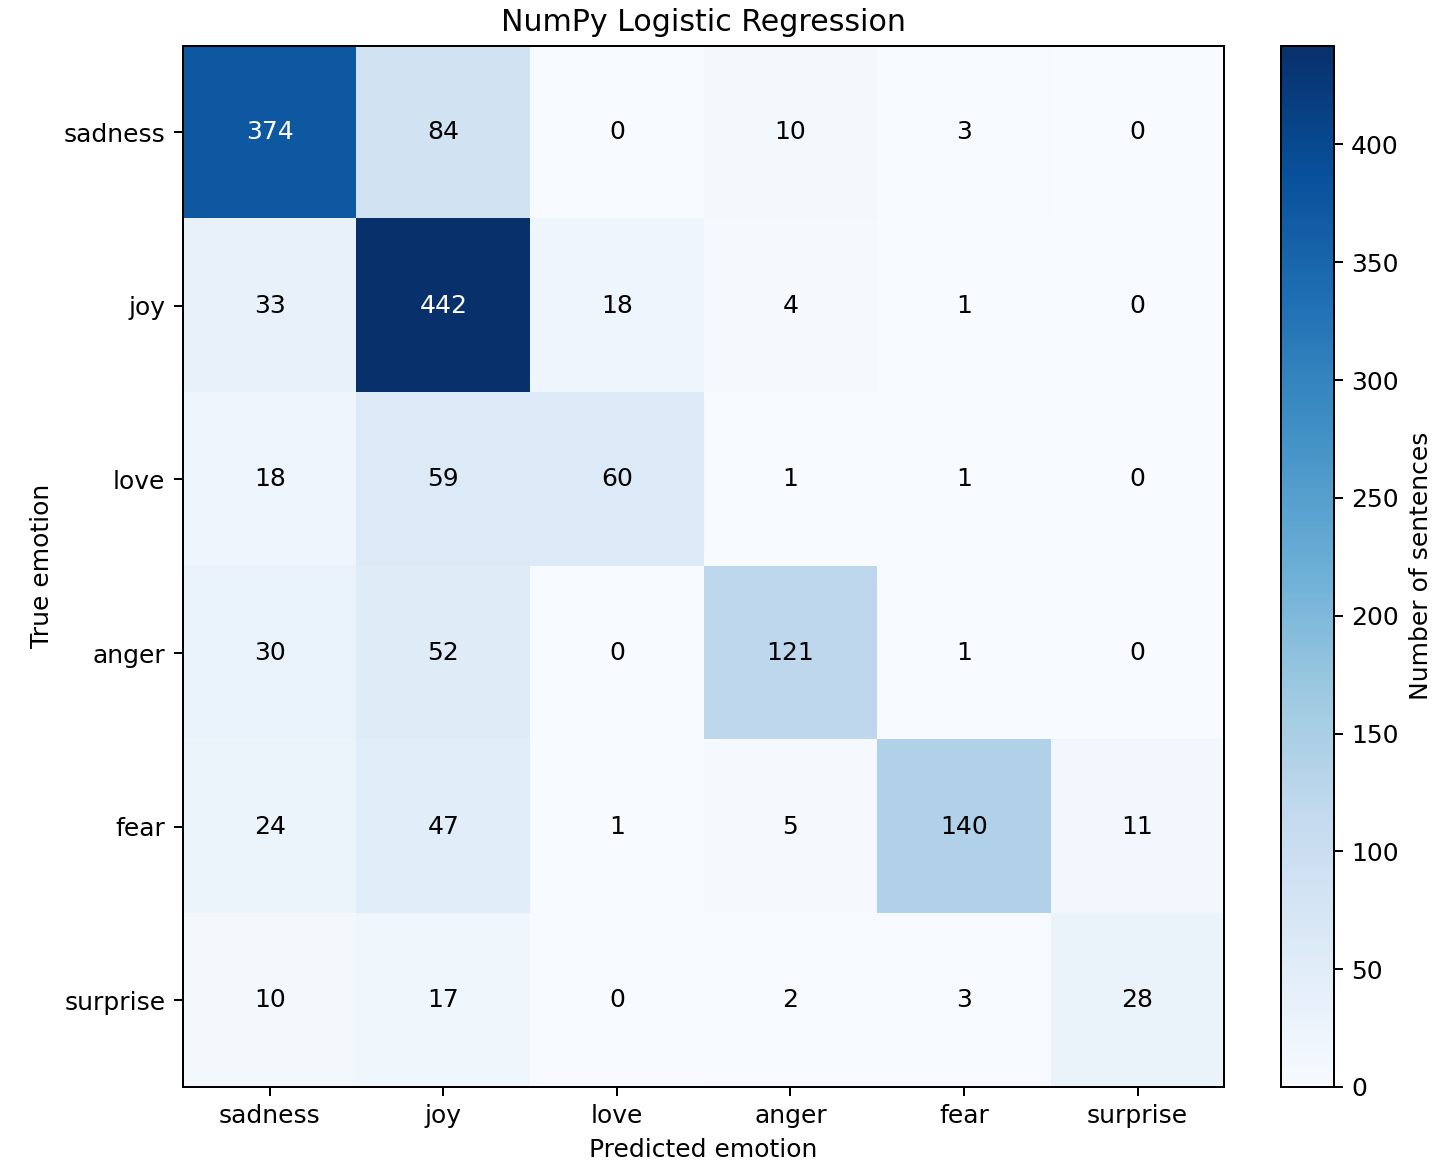

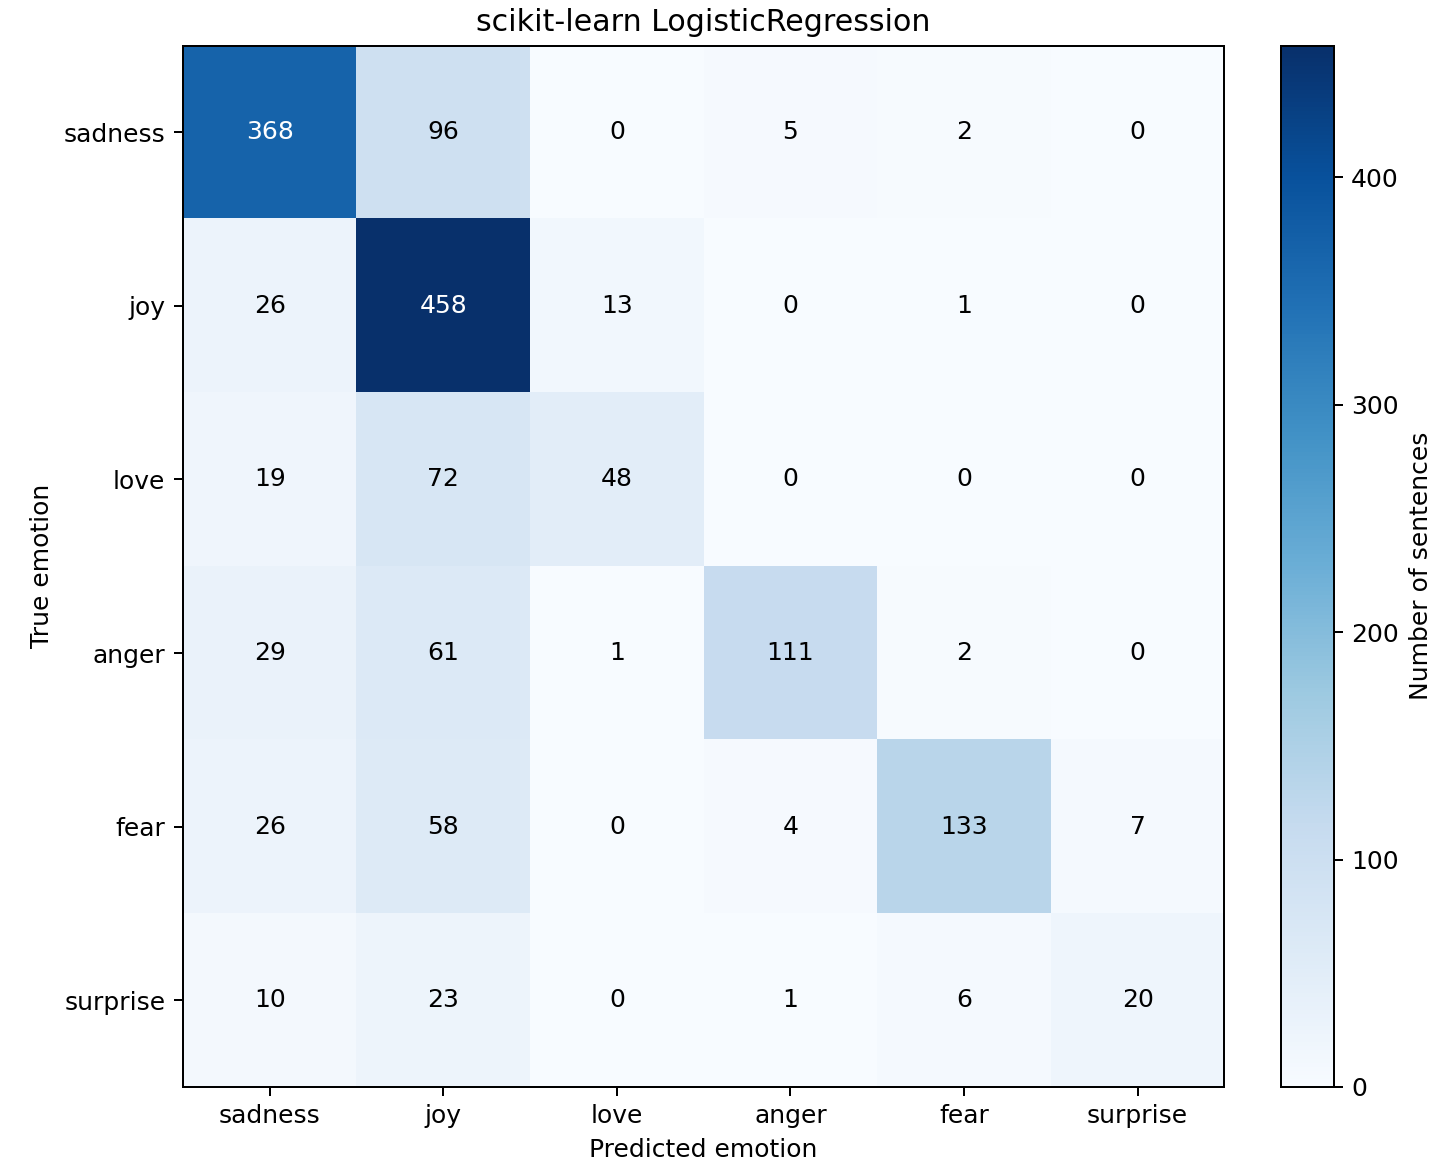

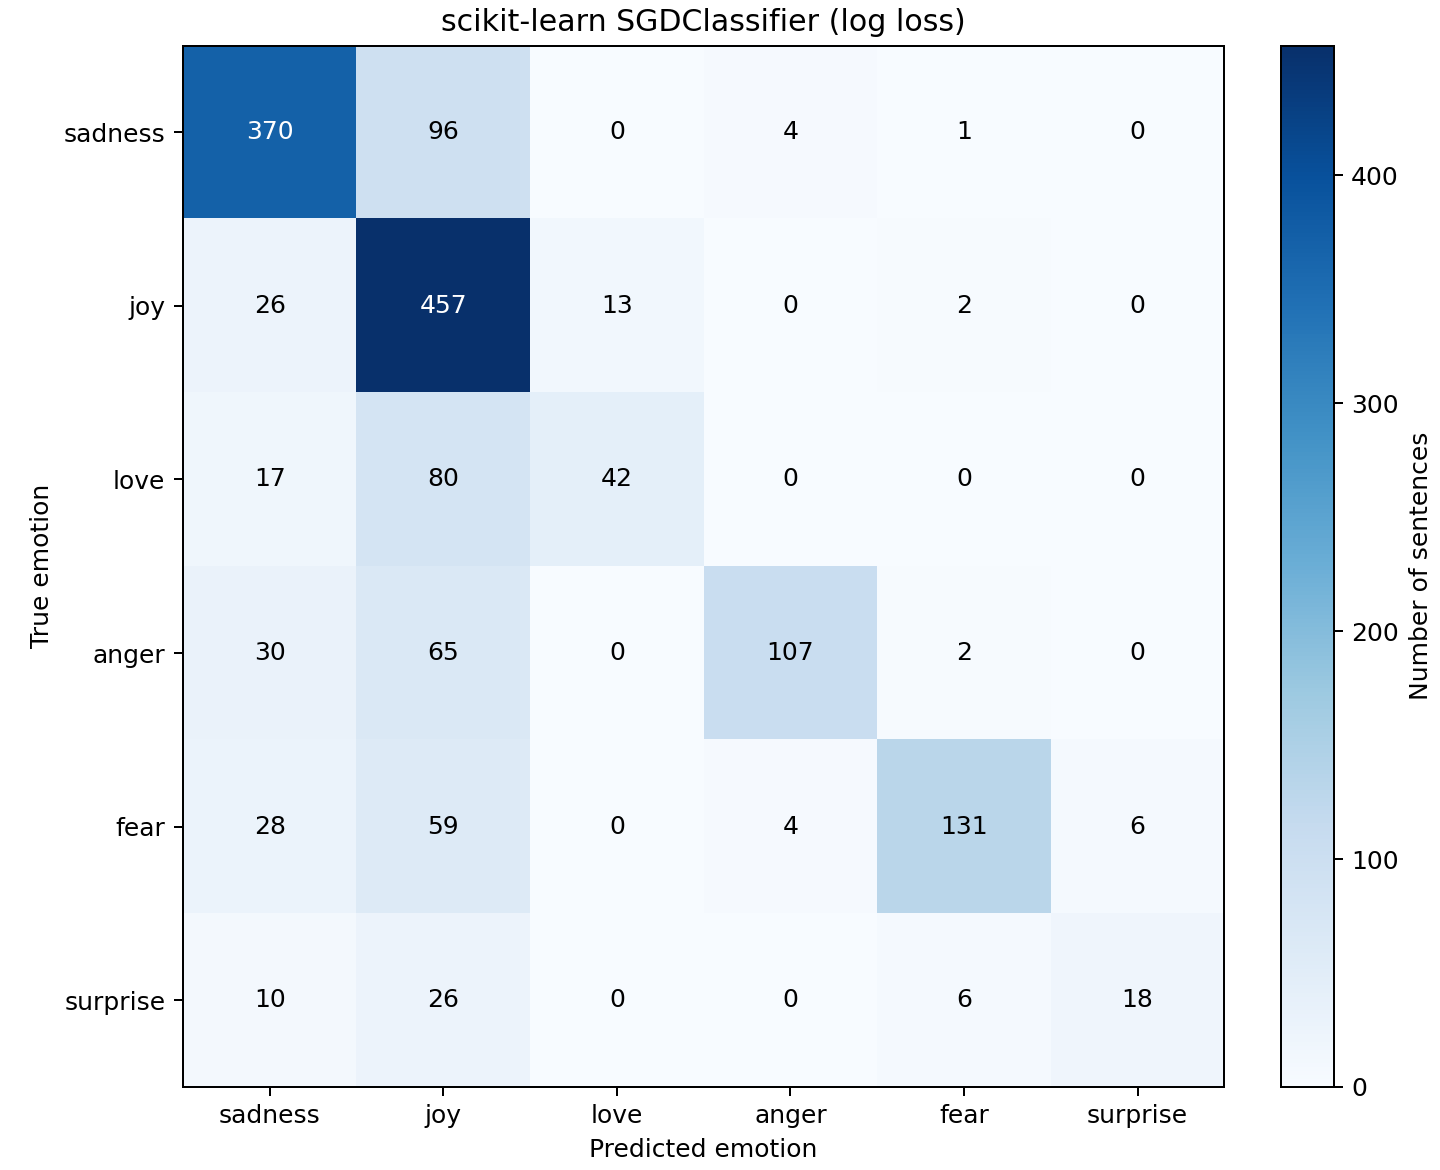

In [15]:
from IPython.display import Image, display

for model_name in results:
    display(Image(filename=str(results_folder / f"{model_name}_confusion_matrix.png")))